In [1]:
# Step 1: Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Step 2: Load the Cleaned Dataset

df = pd.read_csv("../data/processed/penguins_cleaned.csv")

# Step 3: Display First 5 Rows

print("FIRST FIVE ROWS")
display(df.head())

# Step 4: Dataset Shape

print("\nDATASET SHAPE")
print(df.shape)

# Step 5: Dataset Information

print("\nDATASET INFORMATION")
df.info()

# Step 6: Check Missing Values

print("\nMISSING VALUES")
print(df.isnull().sum())

# Step 7: Check Duplicate Rows

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

FIRST FIVE ROWS


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.10,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.50,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.30,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,44.45,17.3,197.0,4050.0,MALE
4,Adelie,Torgersen,36.70,19.3,193.0,3450.0,FEMALE



DATASET SHAPE
(344, 7)

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     344 non-null    float64
 3   bill_depth_mm      344 non-null    float64
 4   flipper_length_mm  344 non-null    float64
 5   body_mass_g        344 non-null    float64
 6   sex                344 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB

MISSING VALUES
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

DUPLICATE ROWS
0


In [2]:
print("Missing Values in Each Column:")
print(df.isnull().sum().to_string())

print("\nBlank Values in Categorical Columns:")
for col in ["species", "island", "sex"]:
    print(col, ":", (df[col].astype(str).str.strip() == "").sum())

print("\nRows with Missing Sex:")
display(df[df["sex"].isnull()])

Missing Values in Each Column:
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0

Blank Values in Categorical Columns:
species : 0
island : 0
sex : 0

Rows with Missing Sex:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex


In [3]:
# Descriptive Statistical Analysis

print("DESCRIPTIVE STATISTICS")

display(df.describe().round(2))

print("\nMEDIAN VALUES")

display(df.select_dtypes(include="number").median().round(2))

print("\nMODE VALUES")

display(df.mode().iloc[0])

DESCRIPTIVE STATISTICS


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,344.00,344.00,344.00,344.00
mean,43.92,17.15,200.89,4200.87
std,5.44,1.97,14.02,799.70
min,32.10,13.10,172.00,2700.00
25%,39.28,15.60,190.00,3550.00
50%,44.45,17.30,197.00,4050.00
75%,48.50,18.70,213.00,4750.00
max,59.60,21.50,231.00,6300.00



MEDIAN VALUES


bill_length_mm         44.45
bill_depth_mm          17.30
flipper_length_mm     197.00
body_mass_g          4050.00
dtype: float64


MODE VALUES


species              Adelie
island               Biscoe
bill_length_mm         41.1
bill_depth_mm          17.0
flipper_length_mm     190.0
body_mass_g          3800.0
sex                    MALE
Name: 0, dtype: object

Species Distribution:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


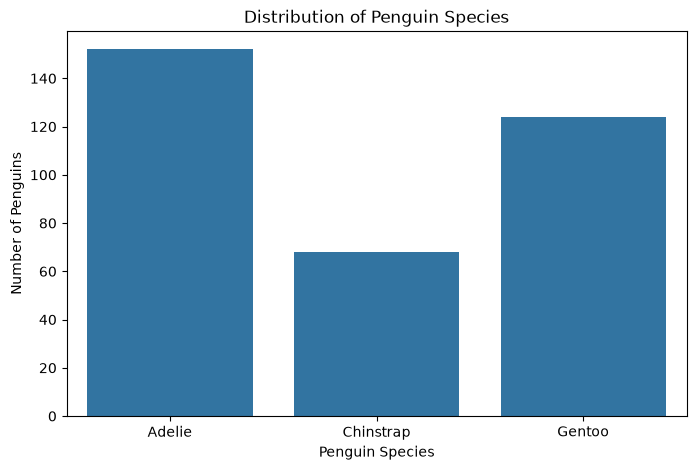

In [4]:
# Species Distribution Analysis

species_counts = df["species"].value_counts()

print("Species Distribution:")
print(species_counts)

# Bar Chart

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="species")

plt.title("Distribution of Penguin Species")
plt.xlabel("Penguin Species")
plt.ylabel("Number of Penguins")

plt.show()

Penguins on Each Island:
island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64


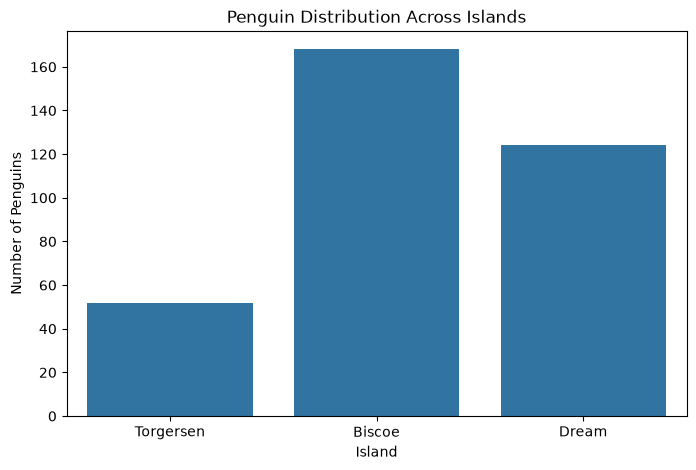

In [5]:
# Island Distribution Analysis

print("Penguins on Each Island:")
print(df["island"].value_counts())

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="island")

plt.title("Penguin Distribution Across Islands")
plt.xlabel("Island")
plt.ylabel("Number of Penguins")

plt.show()

Sex Distribution:
sex
MALE      179
FEMALE    165
Name: count, dtype: int64


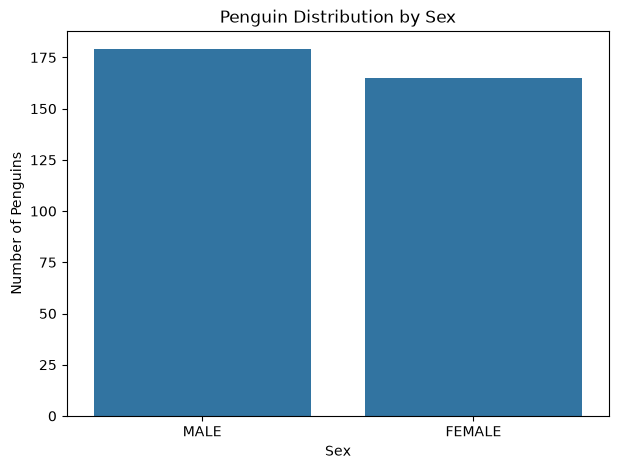

In [6]:
# Sex Distribution Analysis

print("Sex Distribution:")
print(df["sex"].value_counts())

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="sex")

plt.title("Penguin Distribution by Sex")
plt.xlabel("Sex")
plt.ylabel("Number of Penguins")

plt.show()

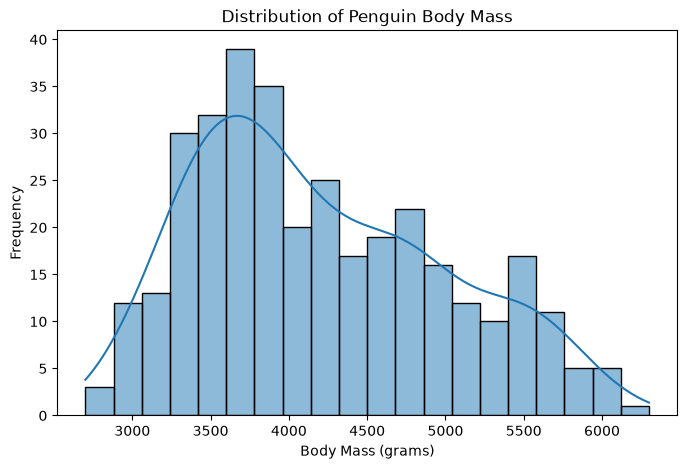

In [7]:
# Body Mass Distribution

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="body_mass_g", bins=20, kde=True)

plt.title("Distribution of Penguin Body Mass")
plt.xlabel("Body Mass (grams)")
plt.ylabel("Frequency")

plt.show()

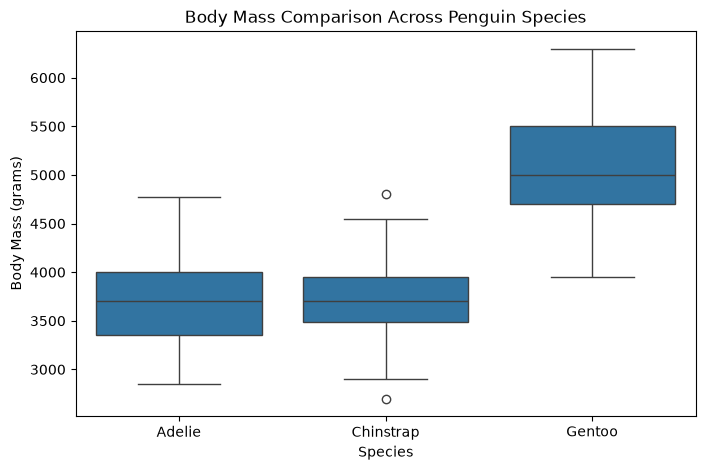

In [8]:
# Body Mass Comparison by Species

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="species", y="body_mass_g")

plt.title("Body Mass Comparison Across Penguin Species")
plt.xlabel("Species")
plt.ylabel("Body Mass (grams)")

plt.show()

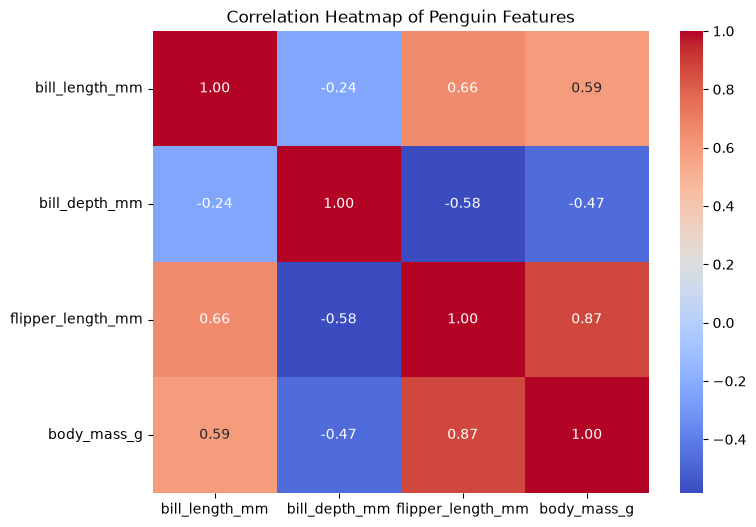

In [9]:
# Correlation Analysis

numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Penguin Features")

plt.show()

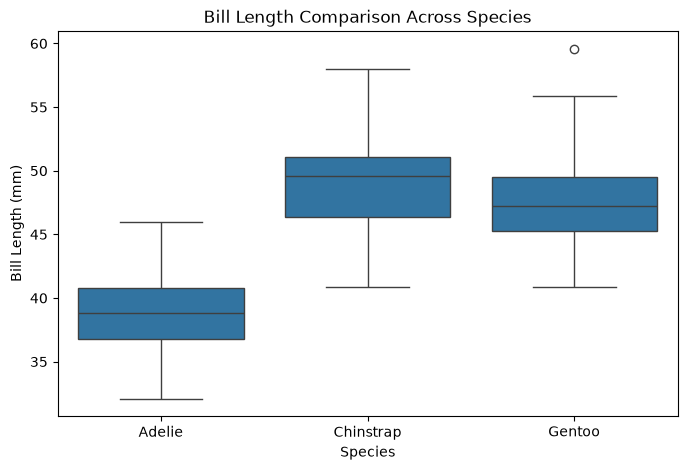

In [10]:
# Bill Length Comparison

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="species",
    y="bill_length_mm"
)

plt.title("Bill Length Comparison Across Species")
plt.xlabel("Species")
plt.ylabel("Bill Length (mm)")

plt.show()

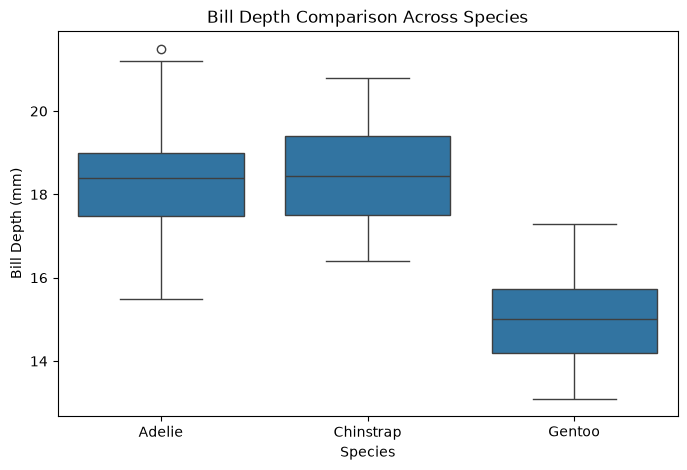

In [11]:
# Bill Depth Comparison

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="species",
    y="bill_depth_mm"
)

plt.title("Bill Depth Comparison Across Species")
plt.xlabel("Species")
plt.ylabel("Bill Depth (mm)")

plt.show()

In [12]:
# Species-wise Average Measurements

species_analysis = df.groupby("species")[
    [
        "bill_length_mm",
        "bill_depth_mm",
        "flipper_length_mm",
        "body_mass_g"
    ]
].mean().round(2)

display(species_analysis)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.83,18.34,190.00,3702.96
Chinstrap,48.83,18.42,195.82,3733.09
Gentoo,47.48,15.00,217.02,5067.74


# Task 2: Exploratory Data Analysis (EDA)
## SWYNEX Technologies – Data Science Internship

### 1. Project Overview
The objective of this task is to perform Exploratory Data Analysis (EDA) on the prepared Palmer Penguins dataset to identify patterns, relationships, distributions, and insights that can support future machine learning models and data-driven decisions.

### 2. Dataset Overview
- Total records: 344
- Total features: 7
- Numerical features: 4
- Categorical features: 3
- Missing values: 0
- Duplicate records: 0

### 3. Statistical Analysis
The dataset was analyzed using mean, median, standard deviation, minimum, maximum, and quartiles.

Key observations:
- Average bill length: 43.92 mm
- Average bill depth: 17.15 mm
- Average flipper length: 200.89 mm
- Average body mass: 4200.87 g

### 4. Visualizations
The following visualizations were created:
1. Penguin species distribution
2. Penguin distribution across islands
3. Penguin distribution by sex
4. Body mass distribution
5. Body mass comparison across species
6. Flipper length vs body mass
7. Correlation heatmap
8. Bill length comparison across species
9. Bill depth comparison across species

### 5. Key Insights

1. **Species Distribution:** Adelie has the highest number of records (152), while Chinstrap has the lowest (68). Class imbalance should be considered during model training.

2. **Island Distribution:** Biscoe has the highest representation with 168 penguins. Island may provide useful information for species prediction.

3. **Sex Distribution:** Male (180) and female (164) records are relatively balanced.

4. **Body Mass Variation:** Body mass varies considerably, with an average of 4200.87 grams.

5. **Species-wise Body Mass:** Gentoo penguins have the highest average body mass (5067.74 g).

6. **Feature Correlation:** Flipper length and body mass have a strong positive correlation of 0.87.

7. **Bill Measurements:** Chinstrap has the highest average bill length (48.83 mm), whereas Gentoo has the lowest average bill depth (15.00 mm).

8. **Flipper Length:** Gentoo penguins have the highest average flipper length (217.02 mm).

9. **Species Classification:** Bill measurements, flipper length, body mass, and island can be useful features for species classification.

### 6. Model and Decision Recommendations
- Consider stratified sampling to preserve species proportions.
- Evaluate class-wise performance instead of relying only on accuracy.
- Use flipper length and body mass as potentially useful predictive features.
- Investigate feature relationships and multicollinearity before model selection.
- Compare models with and without categorical features such as island and sex.

### 7. Conclusion
The EDA revealed meaningful differences in physical characteristics among Adelie, Chinstrap, and Gentoo penguins. Gentoo penguins generally have greater body mass and longer flippers, while bill measurements also show differences between species.

These findings can support future machine learning tasks, especially penguin species classification and body mass prediction.

**Tools Used:** Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook.

In [2]:
%pip install matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.3 MB 1.9 MB/s eta 0:00:05
   --- ------------------------------------ 0.8/9.3 MB 1.7 MB/s eta 0:00:06
   ----- ---------------------------------- 1.3/9.3 MB 1.6 MB/s eta 0:00:05
   ------- -------------------------------- 1.8/9.3 MB 1.8 MB/s eta 0:00:05
   ---------- ----------------------------- 2.4/9.3 MB 2.0 MB/s eta 0:00:04
   ------------- -------------------------- 3.1/9.3 MB 2.2 MB/s eta 0:00:03
   --------------- ------------------------ 3.7/9.3 MB 2.2 MB/s eta 0:00:03
   ------------------- -------------------- 4.5/9.3 MB 2.4 MB/s eta 0:00:03
   --------------------- ------------------ 5.0/9.3 MB 2.4 MB/s eta 0:00:02
   ----------------------- ---------------- 5.5/9.3 MB 2.5 MB/s eta 0:00:02
   ---------------------


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\subha\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip
